In [29]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Реализовать преобразование Хаара (3 ступени сжатия).

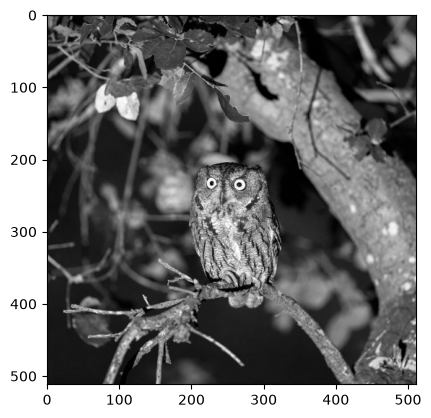

In [30]:
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')

In [31]:
def haar(image, lvls):
    coeffs = image.astype(np.float32)
    for lvl in range(lvls):
        size = coeffs.shape[0] >> lvl
        block = coeffs[:size, :size]
        block = np.hstack(((block[:, 0::2] + block[:, 1::2]) / 2,
                           (block[:, 0::2] - block[:, 1::2]) / 2))
        coeffs[:size, :size] = np.vstack(((block[0::2] + block[1::2]) / 2,
                                          (block[0::2] - block[1::2]) / 2))
    return coeffs

In [32]:
def get_haar_vis(image, lvl):
    coeffs = haar(image, lvl)
    ll_size = 512 >> lvl

    vis_img = np.clip(np.abs(coeffs) * 5, 0, 255)
    vis_img[:ll_size, :ll_size] = coeffs[:ll_size, :ll_size]

    return vis_img

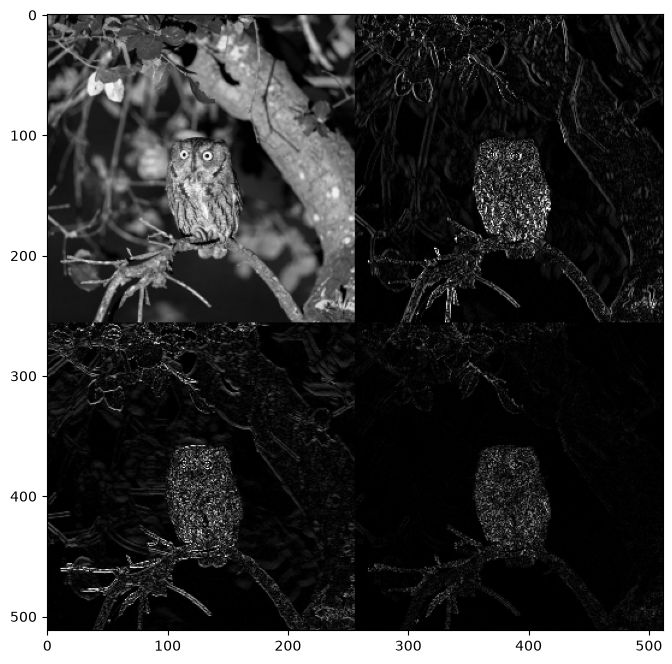

In [33]:
# 1 ступень
plt.figure(figsize=(8, 8))
vis_img1 = get_haar_vis(image, 1)
plt.imshow(vis_img1, cmap='gray')

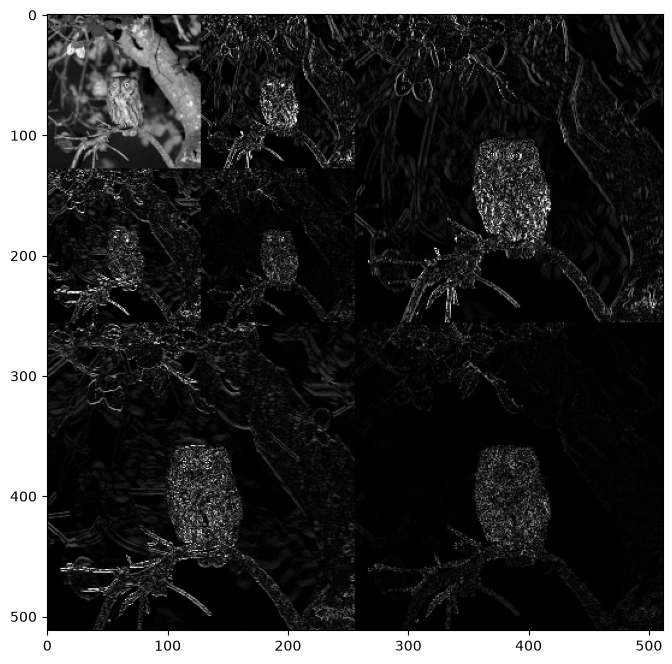

In [34]:
# 2 ступень
plt.figure(figsize=(8, 8))
vis_img2 = get_haar_vis(image, 2)
plt.imshow(vis_img2, cmap='gray')

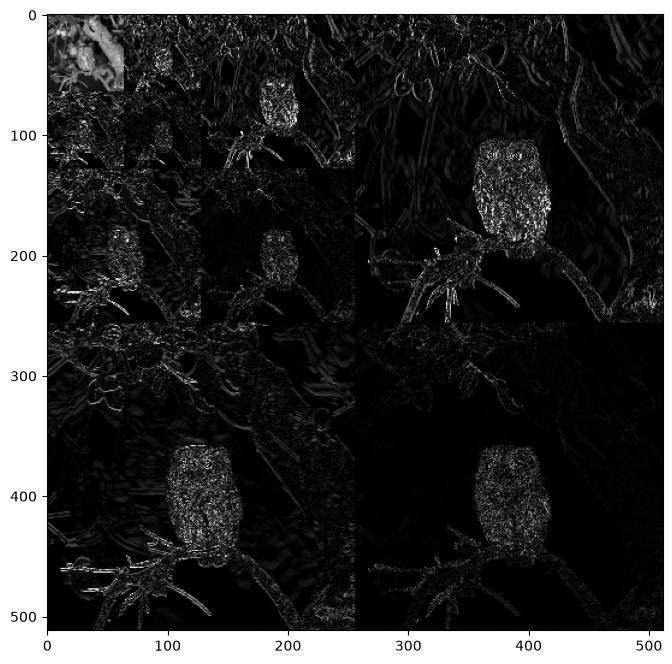

In [35]:
# 3 ступень
plt.figure(figsize=(8, 8))
vis_img3 = get_haar_vis(image, 3)
plt.imshow(vis_img3, cmap='gray')